## Summary to explain non-drift-like behavior to be the potential result of a confounding factors

confounding factors:
- linkage either hitchhiking or epistasis (can not be further seperate with data)
- mutation bias

tested for but not a confounders:
- codon usage bias

## 0. General

### 0.1. Load libraries

In [1]:
import pandas as pd, numpy as np
import networkx as nx

In [2]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.gridspec as gridspec
import matplotlib.patheffects as path_effects

import seaborn as sns

sns.set_theme(style="white", font="Arial")
sns.set_context({'font.size': 10.0, 'axes.labelsize': 12, 'axes.titlesize': 14,
                 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'legend.fontsize': 10,
                 'legend.title_fontsize': None, 'axes.linewidth': 0.8, 'grid.linewidth': 0.8,
                 'lines.linewidth': 1.5, 'lines.markersize': 6.0, 'patch.linewidth': 1.0,
                 'xtick.major.width': 0.5, 'ytick.major.width': 0.5, 'xtick.minor.width': 0.3,
                 'ytick.minor.width': 0.3, 'xtick.major.size': 3.5, 'ytick.major.size': 3.5,
                 'xtick.minor.size': 2.0, 'ytick.minor.size': 2.0,})

plt.rcParams['xtick.bottom'] = True
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']
plt.rcParams['font.size'] = 12
plt.rcParams['xtick.bottom'] = True
plt.rcParams['ytick.left'] = True


### 0.2. General variables

In [3]:
donors = [1,2,3,4]
replicates = ["A", "B", "C"]
passages = list(range(0, 110, 10))
tech_reps = [1,2 ]
populations = ["1A", "1B", "1C", "2A", "2B", "2C", "3A", "3B", "3C", "4A", "4B", "4C"]
segments = ["1-PB2", "2-PB1", "3-PA", "4-HA", "5-NP", "6-NA", "7-M", "8-NS"]
proteins = ['PB2', 'PB1', 'PB1-F2', 'PA', 'PA-X', 'HA', 'NP', 'NA', 'M1', 'M2', 'NEP', 'NS1']


hours_per_passage = 72 #hours
generation_time = 6 #hours > assumption based on Baccam, et al. 2006

In [4]:
segment_cpal = ["#ea5545","#f46a9b", "#ef9b20", "#ede15b", "#87bc45", "#27aeef", "#776efa", "#b33dc6"]
population_cpal = [ "#005fb9", "#58b4e2", "#8ee6ff", "#860041", "#ca0090", "#ff53c0", "#006e00", "#77a908", "#bbe837", "#0000ba", "#5f38ed", "#d49eff" ]
color_list = [ "#f26522", "#d5df24",  "#55adaf", "#351e28"] #for confounding factors, order:  "hitchhiker", "mutation bias",  "co-occurrence", "unexplained"

In [5]:
substitution_types = ["A:T→T:A", "A:T→C:G", "A:T→G:C", "C:G→T:A", "C:G→A:T", "C:G→G:C"]

### 0.3. Functions

## Summary figure

### 1. get data

In [6]:
#load snv summary 
snv_summary = pd.read_csv("../results/snv_summary_annotated_linkage_bias.csv", keep_default_na=False, na_values=[""]).set_index(["population", "refname", "nucpos", "snv"]).sort_index()

#create overview of non-synonymous SNVs (for convienence)
non_synonymous_dict = {segment:[] for segment in segments}
for i in snv_summary[snv_summary["non_synonymous"]==True].index.droplevel(0):
    non_synonymous_dict[i[0]].append(i[-1])


#load trajectories 
trajectories = pd.read_csv("../results/snv_trajectories.csv").set_index(["population", "refname", "nucpos", "snv"]).sort_index()
trajectories = trajectories.rename(columns={c:int(c) for c in trajectories.columns})

driver_passenger_pairs = pd.read_csv("../results/identified_putative_hitchhikers.csv")
cooccurring_pairs = pd.read_csv("../results/identified_putative_coocurring_pairs.csv")

substitution_change_results = pd.read_csv("../results/mutation_bias_per_substitution_type_results.csv").set_index(["population","substitution type"]).sort_index()
sub_shift = pd.read_csv("../results/population_level_mutational_spectrum.csv")

In [7]:
#identify all linked interactions > reduce the number of panels relevant later 
potential_epistatic_interactions = {pop:[] for pop in populations}
for population in populations:
    df = cooccurring_pairs [cooccurring_pairs ["population"]==population]
    if len(df) == 0:
        continue
    G = nx.Graph()

    for _, row in df.iterrows():
        node1 = (row['refname 1'], row['nucpos 1'], row['snv 1'])
        node2 = (row['refname 2'], row['nucpos 2'], row['snv 2'])


        G.add_edge(node1, node2)

    #find cliques
    cliques = list(nx.find_cliques(G))
    cliques = sorted([sorted(c) for c in cliques])
    potential_epistatic_interactions[population] = list(cliques)

Text(0.075, 0.35, 'C')

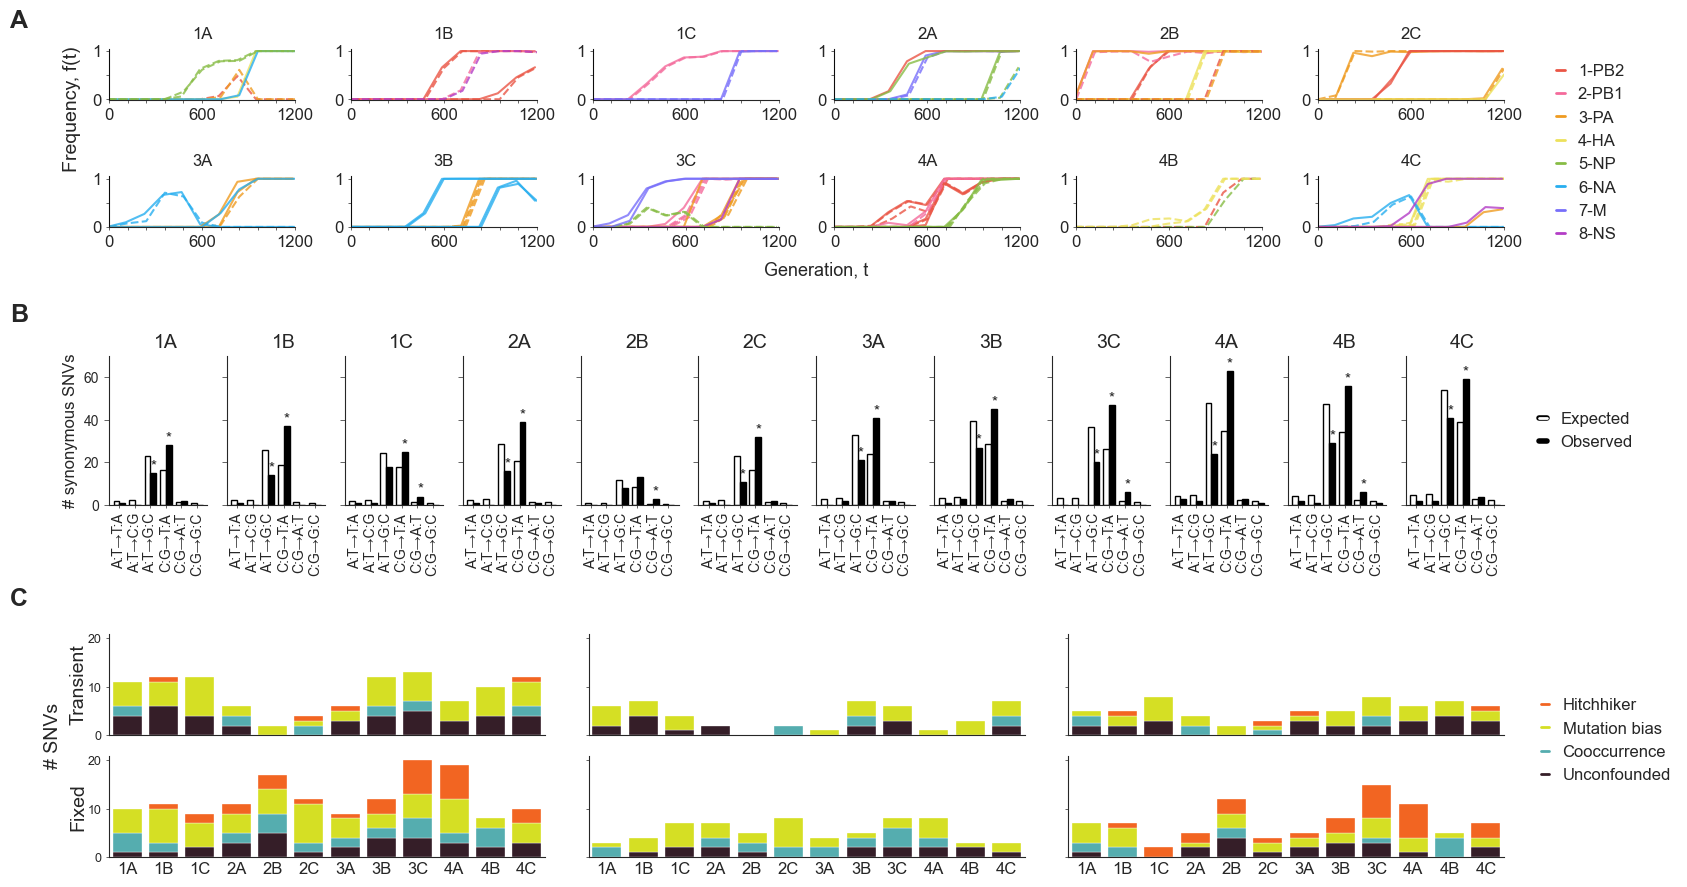

In [8]:
fig = plt.figure(figsize=(18, 10.5))
gs = gridspec.GridSpec(3,1 , wspace=0.3, hspace=0.7, height_ratios=[1.2, 1, 1.5])

#hitchhiker figure
gsi = gridspec.GridSpecFromSubplotSpec(2,6, wspace=0.3, hspace=1.5, subplot_spec=gs[0], )

segment_legend_elements = []#
for i , s in enumerate(segments):
    segment_legend_elements.append(Line2D([0], [0], color=segment_cpal[i], label=s, linewidth=2,  ))
    
offset=1
for i, population in enumerate(populations):
     
    df = driver_passenger_pairs[driver_passenger_pairs["population"]==population].set_index(["driver refname", "driver nucpos", "driver snv"])
    ax = fig.add_subplot(gsi[i])
    
    plotted = []
    
    for j, (driver_refname, driver_nucpos, driver_snv) in enumerate(df.index.unique()):
        if (driver_refname, driver_nucpos, driver_snv) not in plotted:
            freqs = trajectories.loc[(population, driver_refname, driver_nucpos, driver_snv)].values.tolist()
            ax.plot([p-offset for p in passages], freqs, lw=1.5, alpha=0.8, color=segment_cpal[segments.index(driver_refname)])
            plotted.append((driver_refname, driver_nucpos, driver_snv))
        
        sdf = df.loc[[(driver_refname, driver_nucpos, driver_snv)]].reset_index().set_index(['passenger refname', 'passenger nucpos', 'passenger snv'])
        for k, (passenger_refname, passenger_nucpos, passenger_snv) in enumerate(sdf.index):
            if (passenger_refname, passenger_nucpos, passenger_snv) not in plotted:
                freqs = trajectories.loc[(population, passenger_refname, passenger_nucpos, passenger_snv)].values.tolist()
                ax.plot([p+(offset*k) for p in passages], freqs, lw=1.5, alpha=0.8, color=segment_cpal[segments.index(driver_refname)], ls="--")
                plotted.append((passenger_refname, passenger_nucpos, passenger_snv))
            
    for j, snv_list in enumerate(potential_epistatic_interactions[population]):
        
        for k, (refname, nucpos, snv) in enumerate(snv_list):
            if (refname, nucpos, snv) not in plotted:
                freqs = trajectories.loc[(population, refname, nucpos, snv)].values.tolist()
                ls = "-" if snv in non_synonymous_dict[refname] else "--"
                ax.plot([p+(offset*k)-offset for p in passages], freqs, lw=1.5, color=segment_cpal[segments.index(refname)], alpha=0.8, ls=ls )
                plotted.append((refname, nucpos, snv))
         
    ax.spines[['top','right']].set_visible(False)
    ax.set_xlim(-0, passages[-1])
    ax.axvline(0, color="black", zorder=100, lw=0.5)
    
    ax.set_ylim(-0.01,1.05)
    ax.set_yticks([0, 0.5, 1.0])
    ax.set_yticklabels(["0", "", "1"], size=12)


    ax.set_xticks(passages)
    ax.set_xticklabels([])
    ax.tick_params(axis='both', which='both', length=2)  
    ax.set_xticklabels([int((p*hours_per_passage)/generation_time) if p%50==0 else "" for p in passages], size=12)
        
    if i == 8:
        ax.text(120, -1., "Generation, t", size=13, ha="center")
    if i ==0:
        ax.text(-25, -0.2, "Frequency, f(t)", size=14, rotation=90, va="center")
        
    ax.text(50,1.2, population, ha="center", va="bottom", size=12)

    if i==5:
        ax.legend(handles=segment_legend_elements, loc='upper left', bbox_to_anchor=(1.2,1), ncols =1, fontsize=12, handlelength=0.5,
                                edgecolor=None, frameon=False, columnspacing=0.5)    
        
gsi = gridspec.GridSpecFromSubplotSpec(1,12, wspace=0.2, hspace=0., subplot_spec=gs[1], )
for i, population in enumerate(populations):
    ax = fig.add_subplot(gsi[i])
    df = substitution_change_results.loc[population].loc[substitution_types]
    expected = df["exp"].to_dict()
    #expected = {st:row["exp"]/df["exp"].sum() for st, row in df.iterrows()}
    observed = df["obs"].to_dict()
    #observed = {st:row["obs"]/df["obs"].sum() for st, row in df.iterrows()}
    siglabels = {st:"***" if row["p (two-sided)"]<0.001 else  "**" if row["p (two-sided)"]<0.01 else  "*"  if row["p (two-sided)"]<0.05 else "ns" for st,row in df.iterrows()}
    siglabels = {st:  "*"  if row["p (two-sided)"]<0.05 else "ns" for st,row in df.iterrows()}
    
    x = np.arange(len(substitution_types))
    width = 0.38
    ax.bar(x - width / 2,[expected[s] for s in substitution_types], width, label="Expected", color="white", edgecolor="black")
    bars = ax.bar(x + width / 2,[observed[s] for s in substitution_types], width, label="Observed", color="black", edgecolor="black")
    for bar, sub_type in zip(bars, substitution_types):
        if siglabels[sub_type] != "ns":
            ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.025,
                siglabels[sub_type], ha="center", va="bottom", fontsize=11)
    
    ax.set_ylim(0,70)
    ax.spines[['top','right']].set_visible(False)
    if i != 0:
        ax.set_yticklabels([])
    else:
        ax.set_ylabel("# synonymous SNVs", size=12)
    ax.set_xticks(x)
    ax.set_xticklabels(substitution_types, size=10, rotation=90)

    

    ax.text(3, 74, population, ha="center", size=14)
    
    ax.tick_params(axis="x", length=2)

legend_elements = []
for (mt, color) in zip(["Expected", "Observed"], ['white', 'black']):
    legend_elements.append(Line2D([0], [0], color=color, label=mt, linewidth=2,  path_effects=[path_effects.withStroke(linewidth=4, foreground="black")]))
leg = ax.legend(handles=legend_elements, frameon=False, fontsize=12, loc='center left',
                    bbox_to_anchor=(1.2,0.5), ncols =1, handlelength=0.5, edgecolor=None, 
                    columnspacing=0.5)      


#mutation function class
gsij = gridspec.GridSpecFromSubplotSpec(2,3, wspace=0.1, hspace=0.2, subplot_spec=gs[-1], )

mf_all_nondrift_ax,  mf_ns_nondrift_ax, mf_syn_nondrift_ax,  =  fig.add_subplot(gsij[0,0]), fig.add_subplot(gsij[0,1]),fig.add_subplot(gsij[0,2])
mf_all_fix_ax,mf_ns_fix_ax , mf_syn_fix_ax =  fig.add_subplot(gsij[1,0]), fig.add_subplot(gsij[1,1]), fig.add_subplot(gsij[1,2])

labels = ["hitchhiker", "mutation bias",  "co-occurrence", "unexplained"]

legend_elements = []
for (label, color) in zip(labels, color_list):
    if label == "unexplained":
        legend_elements.append(Line2D([0], [0], color=color, label="Unconfounded", linewidth=2,  ))
    else:
        legend_elements.append(Line2D([0], [0], color=color, label=label.capitalize().replace("-", ""), linewidth=2,  ))

for i, non_syn_status in enumerate([[True, False], [True], [False]]):
  
    nondrift_ax = [mf_all_nondrift_ax, mf_ns_nondrift_ax, mf_syn_nondrift_ax][i]   
    fix_ax = [mf_all_fix_ax, mf_ns_fix_ax, mf_syn_fix_ax][i] 
    
    df = snv_summary[snv_summary["non_synonymous"].isin(non_syn_status)].reset_index()
    df = df.drop(columns=["protein", "aapos", "aa_mut", "original_codon", "position_in_codon", "read_base", "read_codon", "non_synonymous"]).drop_duplicates()
    
    for j, row in df.iterrows():
        if pd.notna(row["hitchhiker"]):
            df.loc[j, "cat"] = "hitchhiker"
        elif pd.notna(row["cooccurence"]):
            df.loc[j, "cat"] = "co-occurrence"
        elif pd.notna(row["mutation bias"]):
            df.loc[j, "cat"] = "mutation bias"
        else:
            df.loc[j, "cat"] = "unexplained"
    
    for (ax, status) in zip([nondrift_ax, fix_ax], ["transient", "fixed"]):
        for j, population in enumerate(populations):
            sdf = df[(df["population"]==population)&(df["status"]==status)].groupby("cat")[["snv"]].count()
            bottom = 0
            for (label, color) in zip(labels[::-1], color_list[::-1]):
                try:
                    
                    c =sdf.loc[label,'snv']
                    
                    p = ax.bar(j+0.5, c, bottom=bottom, color=color, edgecolor=None, lw=0.25)
                    bottom += c
                    
                except:
                    continue
        ax.set_ylim(0, 21)
        ax.set_yticks([0, 10, 20])
        if i ==0:
            ax.set_yticklabels([0, 10, 20], size=9)   
        else:
            ax.set_yticklabels([])
        if status == "non-drift":
            ax.text(len(populations)/2, 22, ['All', "Non-synonymous", "Synonymous"][i], ha="center", size=14) 
       
        ax.set_xlim(0, len(populations))
        ax.set_xticks([p+0.5 for p in range(len(populations))])
        if status == "fixed":
            ax.set_xticklabels(populations, size=12)
        else:
            ax.set_xticklabels([])
        ax.tick_params(axis='x', which='both', length=0)
        ax.tick_params(axis='y', which='both', length=2)
        
        ax.spines[['top','right']].set_visible(False)


mf_all_nondrift_ax.text(-1.1, 10.5, "Transient", rotation =90, va="center", size=14,)
mf_all_nondrift_ax.text(-1.8, 0, "# SNVs", rotation =90, va="center", size=14,)

mf_all_fix_ax.text(-1.1, 10.5, "Fixed", rotation =90, va="center", size=14,)

mf_syn_nondrift_ax.legend(handles=legend_elements, loc='center left',
                        bbox_to_anchor=(1.05,-0.05), ncols =1, fontsize=12, handlelength=0.5, edgecolor=None, frameon=False, 
                        columnspacing=0.5)

fig.text(0.075, 0.9, "A", ha="center", size=18, fontweight="bold")
fig.text(0.075, 0.62, "B", ha="center", size=18, fontweight="bold")
fig.text(0.075, 0.35, "C", ha="center", size=18, fontweight="bold")




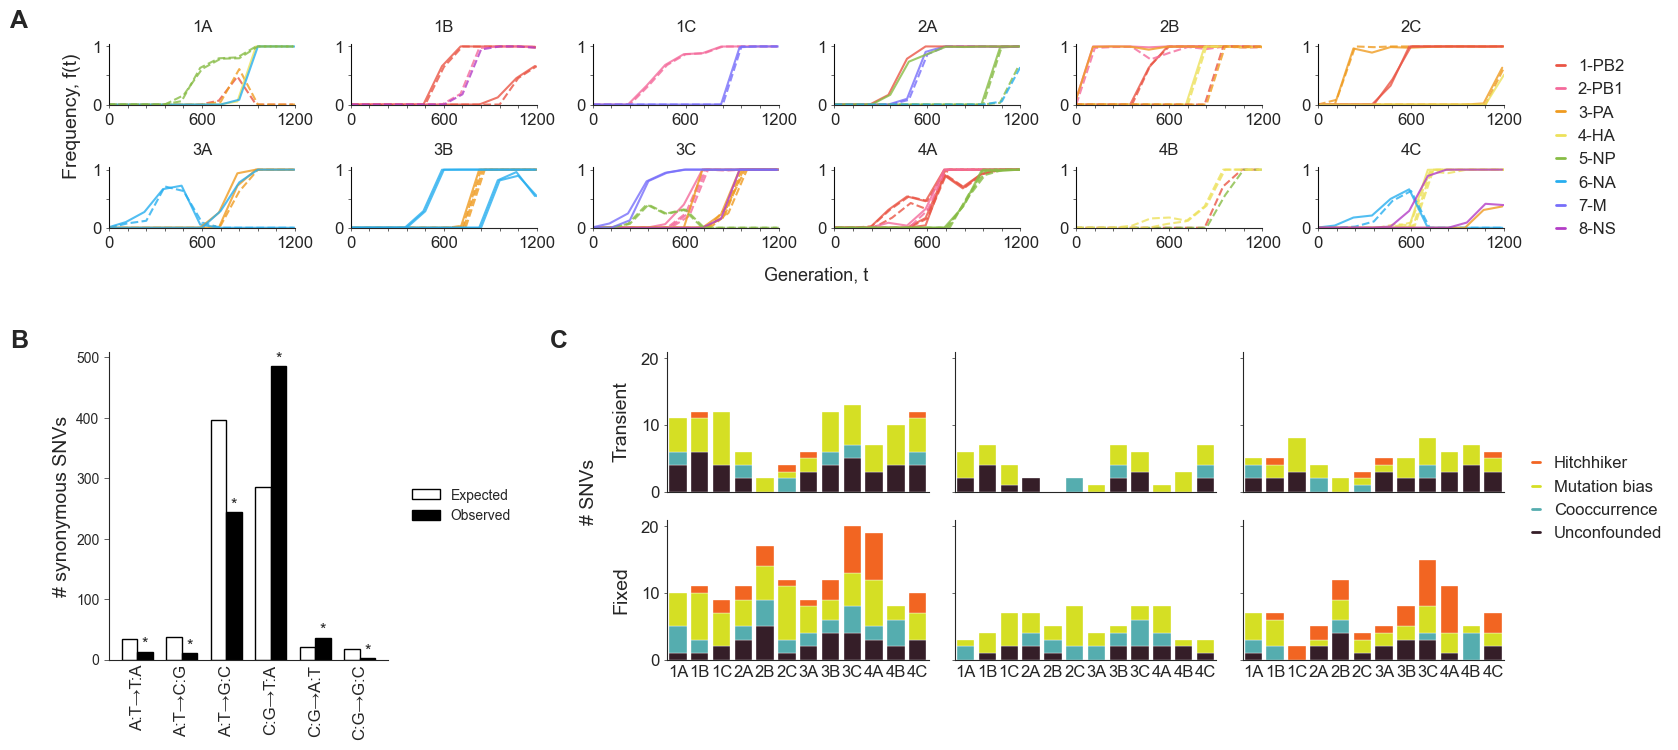

In [9]:
fig = plt.figure(figsize=(18, 8))
gs = gridspec.GridSpec(2,1 , wspace=0.3, hspace=0.5, height_ratios=[1.2, 2])

#Hitchhiker figure 
gsi = gridspec.GridSpecFromSubplotSpec(2,6, wspace=0.3, hspace=1, subplot_spec=gs[0], )

segment_legend_elements = []#
for i , s in enumerate(segments):
    segment_legend_elements.append(Line2D([0], [0], color=segment_cpal[i], label=s, linewidth=2,  ))
    
offset=1
for i, population in enumerate(populations):
     
    df = driver_passenger_pairs[driver_passenger_pairs["population"]==population].set_index(["driver refname", "driver nucpos", "driver snv"])
    ax = fig.add_subplot(gsi[i])
    
    plotted = []
    
    for j, (driver_refname, driver_nucpos, driver_snv) in enumerate(df.index.unique()):
        if (driver_refname, driver_nucpos, driver_snv) not in plotted:
            freqs = trajectories.loc[(population, driver_refname, driver_nucpos, driver_snv)].values.tolist()
            ax.plot([p-offset for p in passages], freqs, lw=1.5, alpha=0.8, color=segment_cpal[segments.index(driver_refname)])
            plotted.append((driver_refname, driver_nucpos, driver_snv))
        
        sdf = df.loc[[(driver_refname, driver_nucpos, driver_snv)]].reset_index().set_index(['passenger refname', 'passenger nucpos', 'passenger snv'])
        for k, (passenger_refname, passenger_nucpos, passenger_snv) in enumerate(sdf.index):
            if (passenger_refname, passenger_nucpos, passenger_snv) not in plotted:
                freqs = trajectories.loc[(population, passenger_refname, passenger_nucpos, passenger_snv)].values.tolist()
                ax.plot([p+(offset*k) for p in passages], freqs, lw=1.5, alpha=0.8, color=segment_cpal[segments.index(driver_refname)], ls="--")
                plotted.append((passenger_refname, passenger_nucpos, passenger_snv))
            
    for j, snv_list in enumerate(potential_epistatic_interactions[population]):
        
        for k, (refname, nucpos, snv) in enumerate(snv_list):
            if (refname, nucpos, snv) not in plotted:
                freqs = trajectories.loc[(population, refname, nucpos, snv)].values.tolist()
                ls = "-" if snv in non_synonymous_dict[refname] else "--"
                ax.plot([p+(offset*k)-offset for p in passages], freqs, lw=1.5, color=segment_cpal[segments.index(refname)], alpha=0.8, ls=ls )
                plotted.append((refname, nucpos, snv))
         
    ax.spines[['top','right']].set_visible(False)
    ax.set_xlim(-0, passages[-1])
    ax.axvline(0, color="black", zorder=100, lw=0.5)
    
    ax.set_ylim(-0.01,1.05)
    ax.set_yticks([0, 0.5, 1.0])
    ax.set_yticklabels(["0", "", "1"], size=12)


    ax.set_xticks(passages)
    ax.set_xticklabels([])
    ax.tick_params(axis='both', which='both', length=2)  
    ax.set_xticklabels([int((p*hours_per_passage)/generation_time) if p%50==0 else "" for p in passages], size=12)
        
    if i == 8:
        ax.text(120, -0.9, "Generation, t", size=13, ha="center")
    if i ==0:
        ax.text(-25, -0.2, "Frequency, f(t)", size=14, rotation=90, va="center")
        
    ax.text(50,1.2, population, ha="center", va="bottom", size=12)

    if i==5:
        ax.legend(handles=segment_legend_elements, loc='upper left', bbox_to_anchor=(1.2,1), ncols =1, fontsize=12, handlelength=0.5,
                                edgecolor=None, frameon=False, columnspacing=0.5)    
     
## mutation bias figure 
gs_ = gridspec.GridSpecFromSubplotSpec(1,2, wspace=0.5, subplot_spec=gs[1], width_ratios=[1,3])
ax = fig.add_subplot(gs_[0])

df = sub_shift.set_index(["substitution type"]).loc[substitution_types]


expected = df["exp"].to_dict()
#expected = {st:row["exp"]/df["exp"].sum() for st, row in df.iterrows()}
observed = df["obs"].to_dict()
#observed = {st:row["obs"]/df["obs"].sum() for st, row in df.iterrows()}
siglabels = {st:"***" if row["p holm"]<0.001 else  "**" if row["p holm"]<0.01 else  "*"  if row["p holm"]<0.05 else "ns" for st,row in df.iterrows()}
siglabels = {st: "*"  if row["p holm"]<0.05 else "ns" for st,row in df.iterrows()}

x = np.arange(len(substitution_types))

width = 0.35

ax.bar(x - width / 2,[expected[s] for s in substitution_types], width, label="Expected", color="white", edgecolor="black")
bars = ax.bar(x + width / 2,[observed[s] for s in substitution_types], width, label="Observed", color="black", edgecolor="black")
for bar, sub_type in zip(bars, substitution_types):
    if siglabels[sub_type] != "ns":
        ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.025,
            siglabels[sub_type], ha="center", va="bottom", fontsize=12)
ax.spines[['top','right']].set_visible(False)
ax.set_ylabel("# synonymous SNVs", size=14)
ax.set_xticks(x)
ax.set_xticklabels(substitution_types, size=12, rotation=90)
ax.tick_params(axis="x", length=0)

leg = ax.legend(frameon=False, fontsize=10, loc='center left',
                        bbox_to_anchor=(1.04,0.5), ncols =1, handlelength=2, edgecolor=None, 
                        columnspacing=0.5)   

#groups
gsij = gridspec.GridSpecFromSubplotSpec(2,3, wspace=0.1, hspace=0.2, subplot_spec=gs_[-1], )

mf_all_nondrift_ax,  mf_ns_nondrift_ax, mf_syn_nondrift_ax,  =  fig.add_subplot(gsij[0,0]), fig.add_subplot(gsij[0,1]),fig.add_subplot(gsij[0,2])
mf_all_fix_ax,mf_ns_fix_ax , mf_syn_fix_ax =  fig.add_subplot(gsij[1,0]), fig.add_subplot(gsij[1,1]), fig.add_subplot(gsij[1,2])

labels = ["hitchhiker", "mutation bias",  "co-occurrence", "unexplained"]

legend_elements = []
for (label, color) in zip(labels, color_list):
    if label == "unexplained":
        legend_elements.append(Line2D([0], [0], color=color, label="Unconfounded", linewidth=2,  ))
    else:
        legend_elements.append(Line2D([0], [0], color=color, label=label.capitalize().replace("-", ""), linewidth=2,  ))

for i, non_syn_status in enumerate([[True, False], [True], [False]]):
  
    nondrift_ax = [mf_all_nondrift_ax, mf_ns_nondrift_ax, mf_syn_nondrift_ax][i]   
    fix_ax = [mf_all_fix_ax, mf_ns_fix_ax, mf_syn_fix_ax][i] 
    
    df = snv_summary[snv_summary["non_synonymous"].isin(non_syn_status)].reset_index()
    df = df.drop(columns=["protein", "aapos", "aa_mut", "original_codon", "position_in_codon", "read_base", "read_codon", "non_synonymous"]).drop_duplicates()
    
    for j, row in df.iterrows():
        if pd.notna(row["hitchhiker"]):
            df.loc[j, "cat"] = "hitchhiker"
        elif pd.notna(row["cooccurence"]):
            df.loc[j, "cat"] = "co-occurrence"
        elif pd.notna(row["mutation bias"]):
            df.loc[j, "cat"] = "mutation bias"
        else:
            df.loc[j, "cat"] = "unexplained"
    
    for (ax, status) in zip([nondrift_ax, fix_ax], ["transient", "fixed"]):
        for j, population in enumerate(populations):
            sdf = df[(df["population"]==population)&(df["status"]==status)].groupby("cat")[["snv"]].count()
            bottom = 0
            for (label, color) in zip(labels[::-1], color_list[::-1]):
                try:
                    
                    c =sdf.loc[label,'snv']
                    
                    p = ax.bar(j+0.5, c, bottom=bottom, color=color, edgecolor=None, lw=0.25)
                    bottom += c
                    
                except:
                    continue
        ax.set_ylim(0, 21)
        ax.set_yticks([0, 10, 20])
        if i ==0:
            ax.set_yticklabels([0, 10, 20], size=12)   
        else:
            ax.set_yticklabels([])
        if status == "non-drift":
            ax.text(len(populations)/2, 22, ['All', "Non-synonymous", "Synonymous"][i], ha="center", size=14) 
       
        ax.set_xlim(0, len(populations))
        ax.set_xticks([p+0.5 for p in range(len(populations))])
        if status == "fixed":
            ax.set_xticklabels(populations, size=12)
        else:
            ax.set_xticklabels([])
        ax.tick_params(axis='x', which='both', length=0)
        ax.tick_params(axis='y', which='both', length=2)
        
        ax.spines[['top','right']].set_visible(False)


mf_all_nondrift_ax.text(-2.5, 10.5, "Transient", rotation =90, va="center", size=14,)
mf_all_nondrift_ax.text(-4, 0, "# SNVs", rotation =90, va="center", size=14,)

mf_all_fix_ax.text(-2.5, 10.5, "Fixed", rotation =90, va="center", size=14,)

mf_syn_nondrift_ax.legend(handles=legend_elements, loc='center left',
                        bbox_to_anchor=(1.05,-0.05), ncols =1, fontsize=12, handlelength=0.5, edgecolor=None, frameon=False, 
                        columnspacing=0.5)

fig.text(0.075, 0.9, "A", ha="center", size=18, fontweight="bold")
fig.text(0.075, 0.5, "B", ha="center", size=18, fontweight="bold")
fig.text(0.375, 0.5, "C", ha="center", size=18, fontweight="bold")

fig.savefig("../figures/fig4_Decomposition_by_confounding_factors.svg", dpi=300,bbox_inches='tight')#
fig.savefig("../figures/fig4_Decomposition_by_confounding_factors.png", dpi=300,bbox_inches='tight')  
       

**Figure 4 Decomposition of non-drift-like SNV trajectories by potential confounding factors.** **A**, SNV frequency trajectories with evidence for putative linkage (both hitchhiker and cooccurring pairs) per population. SNV trajectories are coloured by segment. Solid and dotted lines indicate non-synonymous and synonymous SNVs, respectively. Annotated version in Supplemental Figure S5. **B**, Pooled expected and observed mutational spectrum for synonymous SNVs within the non-overlapping ORFs for PB1, PB2, PA, HA, NP, and NA. Asterisk indicates Holm-adjusted P<0.05 (binomial test). **C**, Number of SNVs by non-neutral classification and substitution type per population coloured by putative confounder. SNVs confounded by both putative linkage and mutation bias are coloured by linkage. Only the passenger in the hitchhiker pair is coloured, whereas both cooccurring SNVs within the pair are coloured. 